# Experiment 3 — Adversarial Faithfulness Challenge

**H3.** Qwen3 may explain a fitted model less faithfully when its local contributions conflict with familiar clinical expectations. The primary outcome is the mean counterintuitive-minus-intuitive difference in signed top-three agreement, separately for A, B, and C. Negative differences indicate worse agreement under reversal. Explicit intuitive-direction claims and within-profile direction switches characterize how any difference arises.

Experiment 1 produced the pinned MIMIC-IV model and saved SHAP data. Experiment 2 evaluated A/B/C on 72 saved cases. Here the primary experiment holds fictional patient features fixed while swapping synthetic coefficient vectors. The real XGBoost model and its predictions stay frozen.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

for source in (Path.cwd(), Path.cwd() / "src", Path.cwd() / "HRP" / "src"):
    if (source / "adversarial_runner.py").is_file():
        sys.path.insert(0, str(source))
        break

from adversarial_analysis import predicted_risk_sensitivity
from adversarial_figures import build_figures
from adversarial_observational import screen_saved_cases
from adversarial_runner import notebook_run
from llm_runner import ModelConfig

MODE = "auto"
RUN_DIRECTORY = None  # Optional dedicated private Experiment 3 run directory.
SAVE_BUNDLE = False
RUN_OFFLINE_SMOKE = False
SCREEN_PINNED_MIMIC = False
MAX_CALLS = None
RUNTIME_SECONDS = 14_400
MODEL_DIGEST = None  # Optional digest pin for qwen3:8b.

## Synthetic profiles and model reversals

The six pilot features use fictional values. Age spans 20–90 years, prior admissions 0–8, creatinine 0.45–3.50 mg/dL, hemoglobin 7–18 g/dL, sodium 120–153 mmol/L, and heart rate 45–145 bpm. Seeded draws generate separate training-background and candidate pools.

The intuitive reference uses the pilot's per-unit weights. A value above the background mean is assumed to have a positive attribution for each target before reversal. These directions are experimental assumptions. Each counterintuitive variant flips only the designated coefficients. A model-specific raw intercept holds the reference margin at −1.45. Model probabilities change and may give A an indirect signal about the model switch.

## Scenario eligibility, matched sampling and SHAP validation

Both targeted contributions must be at least +0.12 raw log-odds under the intuitive model and at most −0.12 under its paired variant. Conflicting importance requires the prespecified salient feature, creatinine or age, to rank outside the top three, have magnitude at most 0.16, and trail the dominant feature by at least 0.24. Mixed direction requires a contribution of at least +0.12 and one of at most −0.12 among the top three. These properties can overlap.

Each family draws up to 24 eligible profiles from 8,192 candidates by cycling through available strata. Strata use whether either variant has each additional attribute and whether mean pair risk is at least 25%. Eligibility uses the SHAP reference alone. Unequal stratum availability is visible in the manifest.

Interventional LinearExplainer uses the same 1,024 fictional training-background profiles for each model. Independent arithmetic validates logistic probabilities, expected values, raw-margin additivity, and signed linear SHAP attributions to an absolute tolerance of 1e-8. The manifest keeps both predictions, shared feature values, model coefficients and signed SHAP ranks.

In [2]:
run = notebook_run(MODE, directory=RUN_DIRECTORY, config=ModelConfig(digest=MODEL_DIGEST),
                   max_calls=MAX_CALLS, runtime_seconds=RUNTIME_SECONDS, save=SAVE_BUNDLE)
manifest, results = run["manifest"], run["result"]

In [3]:
display(pd.DataFrame(manifest["feature_schema"]))
display(pd.DataFrame([
    {"model": model, "raw intercept": spec["intercept"], **spec["coefficients"]}
    for model, spec in manifest["models"].items()
]).round(5))
display(Markdown("**Table 1. Eligible and selected scenario records**"))
display(pd.DataFrame(manifest["selection_counts"]))
display(pd.DataFrame(manifest["sampling_strata"]))
display(pd.DataFrame({k: m["max_errors"] for k, m in manifest["models"].items()}).T)

,pilot_column,name,label,unit,pilot_weight
0,age_years,age,Age,years,0.032
1,prior_admissions,prior_admissions,Prior hospital admissions,admissions,0.440
2,creatinine_mg_dl,creatinine,Creatinine,mg/dL,0.800
3,hemoglobin_g_dl,hemoglobin,Hemoglobin,g/dL,-0.110
4,sodium_mmol_l,sodium,Sodium,mmol/L,-0.035
5,heart_rate_bpm,heart_rate,Heart rate,bpm,0.014


,model,raw intercept,age,prior_admissions,creatinine,hemoglobin,sodium,heart_rate
0,renal-utilization-intuitive,0.33680,0.032,0.44,0.8,-0.11,-0.035,0.014
1,renal-utilization-counterintuitive,3.28180,0.032,-0.44,-0.8,-0.11,-0.035,0.014
2,age-physiology-intuitive,0.33680,0.032,0.44,0.8,-0.11,-0.035,0.014
3,age-physiology-counterintuitive,6.28528,-0.032,0.44,0.8,-0.11,-0.035,-0.014


**Table 1. Eligible and selected scenario records**

,family,variant,category,reversed_features,candidates,eligible,selected,shap_validation
0,renal-utilization,intuitive,intuitive,[],8192,1093,24,passed
1,renal-utilization,intuitive,conflicting_importance,[],8192,89,8,passed
2,renal-utilization,intuitive,mixed_direction,[],8192,649,10,passed
3,renal-utilization,counterintuitive,counterintuitive,"[creatinine, prior_admissions]",8192,1093,24,passed
4,renal-utilization,counterintuitive,conflicting_importance,"[creatinine, prior_admissions]",8192,89,8,passed
5,renal-utilization,counterintuitive,mixed_direction,"[creatinine, prior_admissions]",8192,645,14,passed
6,age-physiology,intuitive,intuitive,[],8192,989,24,passed
7,age-physiology,intuitive,conflicting_importance,[],8192,31,11,passed
8,age-physiology,intuitive,mixed_direction,[],8192,590,11,passed
9,age-physiology,counterintuitive,counterintuitive,"[age, heart_rate]",8192,989,24,passed


,family,either_conflicting,either_mixed,high_pair_mean_risk,eligible,selected
0,renal-utilization,False,False,False,10,5
1,renal-utilization,False,False,True,2,2
2,renal-utilization,False,True,False,573,5
3,renal-utilization,False,True,True,419,4
4,renal-utilization,True,True,False,57,4
5,renal-utilization,True,True,True,32,4
6,age-physiology,False,False,False,3,3
7,age-physiology,False,True,False,557,5
8,age-physiology,False,True,True,398,5
9,age-physiology,True,False,False,1,1


,additivity,analytic_shap,expected_value,probability
renal-utilization-intuitive,1.332268e-15,0.0,0.000000e+00,0.0
renal-utilization-counterintuitive,2.220446e-15,0.0,2.220446e-16,0.0
age-physiology-intuitive,1.776357e-15,0.0,0.000000e+00,0.0
age-physiology-counterintuitive,3.552714e-15,0.0,2.220446e-16,0.0


## Explanation conditions and local Qwen3

A sees feature values, labels, units, and model probability. B receives the same inputs plus SHAP expected value, signed contributions, ranks, and output scale. Evaluator labels, IDs and coefficients stay in the manifest. C uses the exact B draft and the Experiment 2 verifier, one optional Qwen3 revision, and a checked deterministic fallback. C measures verified system delivery. Revision acceptance separately measures Qwen3's correction ability.

Ollama runs Qwen3 8B with seed 42, temperature 0, context 4,096, a 512-token generation cap, JSON mode and thinking disabled. Real mode validates the installed digest.

## Offline fictional validation

The scripted exercise checks abstention, contradictory grounded drafts, one accepted revision and one deterministic fallback. The primary H3 analysis uses live Qwen3 results.

In [4]:
if RUN_OFFLINE_SMOKE:
    with TemporaryDirectory(prefix="hrp-experiment3-offline-") as directory:
        smoke = notebook_run("fictional", directory=directory)
        display(smoke["result"]["operations"])
        display(pd.DataFrame(smoke["result"]["interventions"]))

## Execution and reproducibility

Auto mode loads a completed checkpoint for offline review or shows setup if none exists. The reference run validates the saved scenario fingerprint, model digest, shared code and input fingerprints before scoring. It uses the saved coefficients, background metadata, and local SHAP references directly. Review neither resamples profiles nor calls Ollama. Leave bundle export disabled to keep all reference files intact.

Fictional mode is an optional scripted software check. Real mode explicitly starts or resumes local inference. The published results below are from the completed reference checkpoint.

In [5]:
if results:
    saved = run["state"]["manifest"]
    provenance = saved["provenance"]
    display(pd.Series({
        "Execution / review mode": f'{run["execution_mode"]} / {run["mode"]}',
        "Checkpoint SHA-256": run["checkpoint_sha256"],
        "Scenario manifest fingerprint": provenance["scenario_manifest_sha256"],
        "Fixed background fingerprint": manifest["reference"]["background_sha256"],
        "Checkpoint format": saved["checkpoint_version"],
        "Runner": provenance["runner_version"],
        "Scenarios": provenance["scenario_version"],
        "Prompt": saved["prompt_version"],
        "Verifier": saved["verifier_version"],
        "Scorer": saved["scorer_version"],
        "Analysis": results["version"],
        "Model digest": saved["configuration"]["model"]["digest"],
    }, name="Run provenance").to_frame())
    counts = results["operations"]["statuses"]
    display(Markdown(
        f'**{results["operations"]["records"]} condition records.** '
        f'{counts.get("ok", 0)} valid, {counts.get("parse_error", 0)} terminal parse failures, '
        f'{counts.get("inference_error", 0)} terminal inference failures, {counts.get("pending", 0)} pending.'
    ))
    figures = build_figures(results)
    for figure in figures.values():
        plt.close(figure)
else:
    display(Markdown("**Setup complete.** No completed checkpoint was loaded."))

,Run provenance
Execution / review mode,real / review
Checkpoint SHA-256,52ecf7c17a9cfd9108c264af7e8f0886a1754be23edfb2...
Scenario manifest fingerprint,68387030b1bd39b0bc243a81704624a0bc9c1f19bb2bac...
Fixed background fingerprint,d44d5cb9c172391c16301f3f0e96d5aa953b955092773a...
Checkpoint format,2
Runner,experiment3-runner-v1
Scenarios,experiment3-scenarios-v1
Prompt,experiment2-v3
Verifier,experiment2-verifier-v3
Scorer,experiment2-scorer-v1


**288 condition records.** 282 valid, 6 terminal parse failures, 0 terminal inference failures, 0 pending.

## Structured attribution and narrative coverage

Signed agreement counts feature and direction matches among the reference top three. Exact ordering concerns rank. Narrative faithfulness uses the Experiment 2 grammar and stays separate from structured agreement. Parser coverage is checked attribution clauses divided by checked plus ambiguous clauses. Case-level scores retain mismatches, omissions, unsupported claims and prose completeness.

,condition,variant,valid,total,signed_top_three_agreement,exact_top_three_ordering,structured_correct,parser_coverage
0,A,intuitive,44,48,1.659,0.045,0.000,0.000
1,A,counterintuitive,46,48,0.652,0.043,0.000,0.016
2,B,intuitive,48,48,2.958,0.771,0.771,0.000
3,B,counterintuitive,48,48,2.729,1.000,0.875,0.000
4,C,intuitive,48,48,3.000,1.000,1.000,1.000
5,C,counterintuitive,48,48,3.000,1.000,1.000,1.000


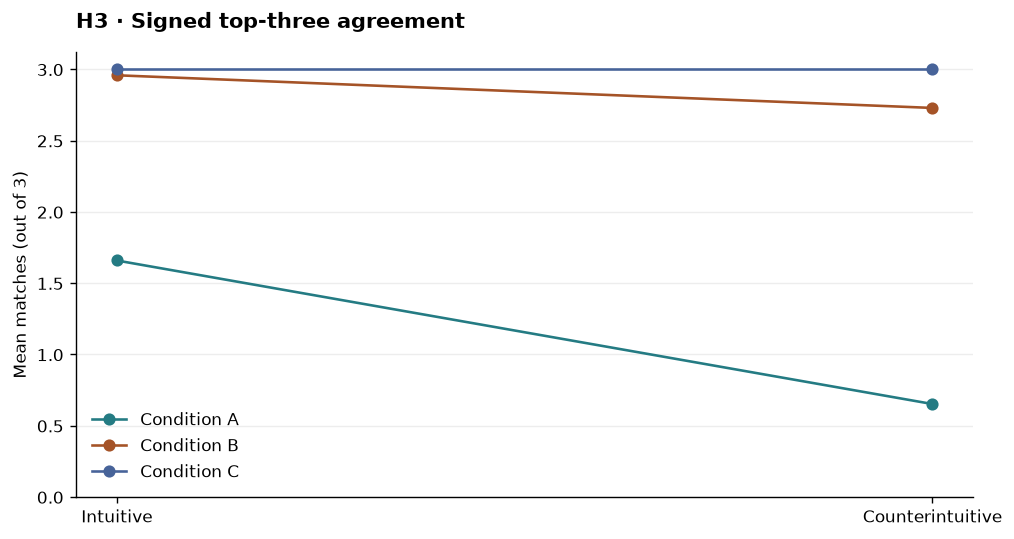

In [6]:
if results:
    faithfulness = pd.DataFrame(results["faithfulness"])
    display(faithfulness[["condition", "variant", "valid", "total", "signed_top_three_agreement",
                          "exact_top_three_ordering", "structured_correct", "parser_coverage"]].round(3))
    display(figures["01_h3_interaction"])

## Clinical-expectation substitution and model switching

**Structured clinical-expectation substitution** counts an explicit JSON driver direction that matches the prespecified intuitive expectation and contradicts the saved SHAP direction. It measures reported directions. An inference about the model's reasoning would require different evidence.

The **combined structured-and-prose rubric** distinguishes model-faithful responses, substitution, other incorrect attribution, abstention or omission, and unverifiable responses. A direction that appears in ambiguous prose stays unverifiable under this rubric. Human interpretation can establish what particular prose communicates, as illustrated below. The automated combined count depends on parser coverage.

The switch analysis compares the same profile across models. A correct switch requires agreement on both sides of the reference sign change. A retained intuitive direction was initially faithful and persisted after reversal. The table focuses on targets ranked in the top three in both models. The full replay retains results for all targets.

**Structured clinical-expectation substitution · Counterintuitive targeted features**

,outcome,abstention,clinical_expectation_substitution,model_faithful,other_incorrect,unverifiable
condition,denominator,,,,,
A,96,15,71,6,0,4
B,96,39,10,47,0,0
C,96,39,0,57,0,0


**Combined structured-and-prose outcomes · Counterintuitive targeted features**

,outcome,abstention,clinical_expectation_substitution,model_faithful,other_incorrect,unverifiable
condition,denominator,,,,,
A,96,14,11,2,0,69
B,96,38,0,1,0,57
C,96,39,0,57,0,0


**Structured-only model switching · Top three in both models**

,outcome,abstention,correct_switch,other_incorrect,retained_intuitive_direction,unverifiable
condition,denominator,,,,,
A,57,7,0,0,45,5
B,57,1,46,0,10,0
C,57,0,57,0,0,0


**Prose-dependent model switching · Top three in both models**

,outcome,abstention,correct_switch,other_incorrect,retained_intuitive_direction,unverifiable
condition,denominator,,,,,
A,57,6,0,0,2,49
B,57,0,0,0,0,57
C,57,0,57,0,0,0


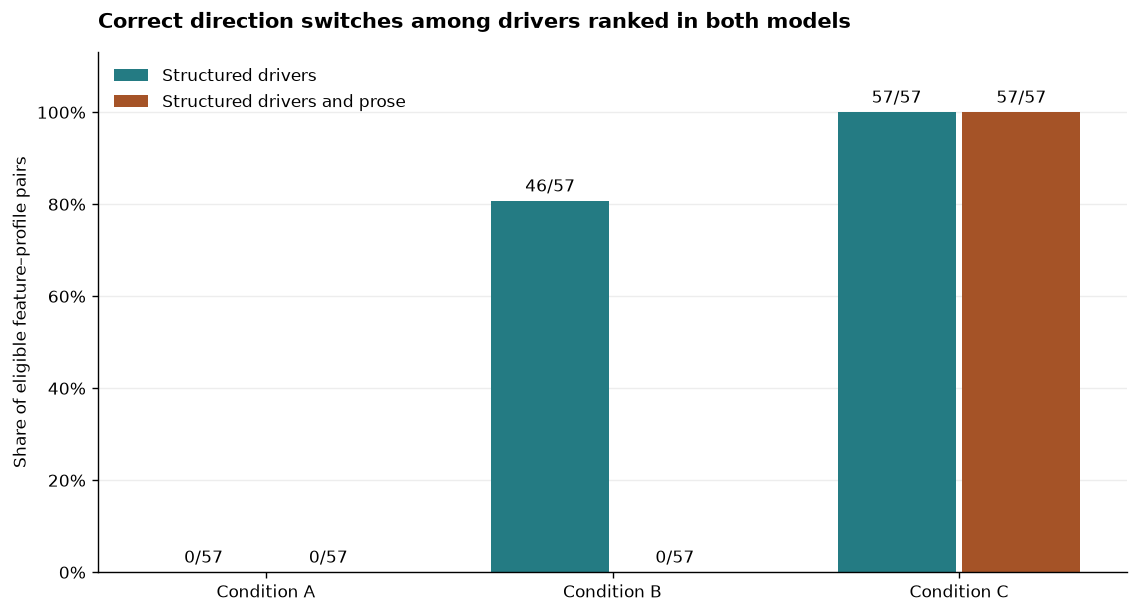

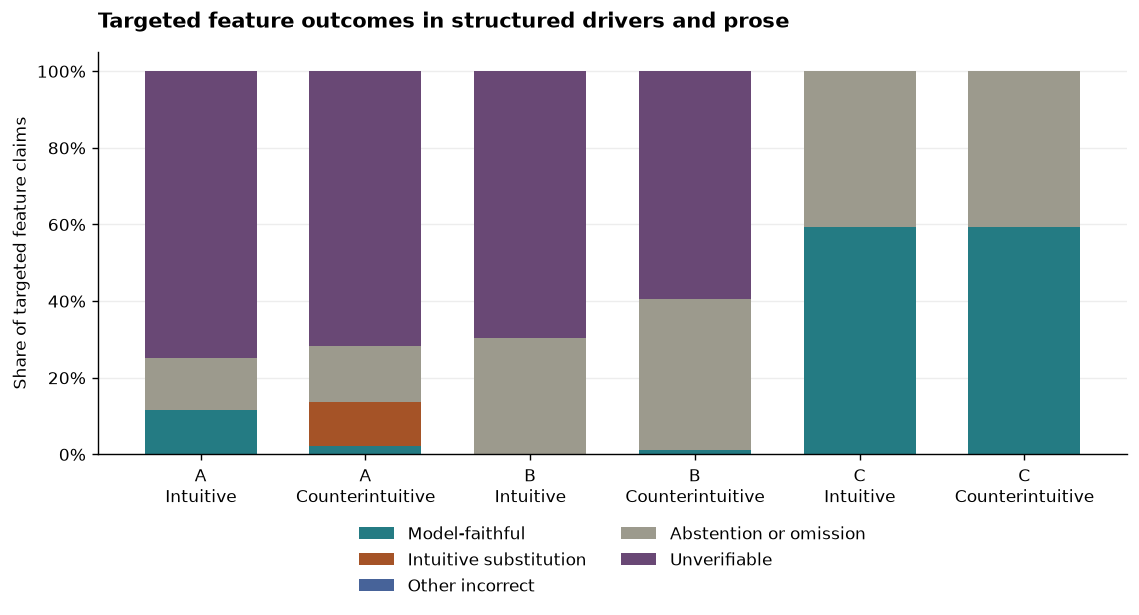

In [7]:
if results:
    for key, title in (("structured_claim_rates", "Structured clinical-expectation substitution"),
                       ("claim_rates", "Combined structured-and-prose outcomes")):
        table = pd.DataFrame(results[key]).query("variant == 'counterintuitive' and not top_three_only")
        display(Markdown(f"**{title} · Counterintuitive targeted features**"))
        display(table.pivot(index=["condition", "denominator"], columns="outcome", values="count"))
    for key, title in (("structured_switch_rates", "Structured-only model switching"),
                       ("switch_rates", "Prose-dependent model switching")):
        table = pd.DataFrame(results[key]).query("top_three_in_both_only")
        display(Markdown(f"**{title} · Top three in both models**"))
        display(table.pivot(index=["condition", "denominator"], columns="outcome", values="count"))
    display(figures["02_model_switch"], figures["03_clinical_substitution"])

## Verification outcomes and exploratory probes

Condition B measures the original grounded draft. An accepted Qwen3 revision measures model correction after feedback. A deterministic fallback instead uses the saved SHAP reference to construct the final explanation. Final verified completeness measures the system end to end.

An intervention can reflect an attribution error, an incomplete response, unfamiliar prose, or multiple issues. C requires a supported direction in prose for each top-three driver. The saved B drafts had low automated coverage, so an intervention count alone cannot quantify semantic errors.

The fictional probes illustrate specific software behavior. An explicit contradiction and an ambiguous rejection are different outcomes. The missing-directions probe is incomplete under the release rule. The only complete error-free control tests acceptance on one known input. The probes provide no population estimates of sensitivity or specificity. Their accepted revisions are scripted.

,variant,completed,interventions,intervention_rate,revision_accepted,revision_rejected,fallback_used,verified_complete
0,intuitive,48,48,1.0,4,44,44,48
1,counterintuitive,48,48,1.0,3,45,45,48


,probe,expected_error,detected,missed,ambiguous,draft_accepted,corrected_with_scripted_revision,corrected_with_fallback
0,correct control,False,False,False,False,True,False,False
1,wrong direction in prose,True,True,False,False,False,True,True
2,wrong structured direction,True,True,False,False,False,True,True
3,outside top three called strongest,True,True,False,False,False,True,True
4,compound contradiction,True,True,False,False,False,True,True
5,relative clause contradiction,True,False,False,True,False,True,True
6,unsupported causation,True,True,False,False,False,True,True
7,missing directions,False,False,False,False,False,True,True


,Exploratory probe counts
Explicitly detected errors,5
Ambiguous errors rejected without explicit detection,1
Errors silently missed and accepted,0
Complete correct controls rejected,0


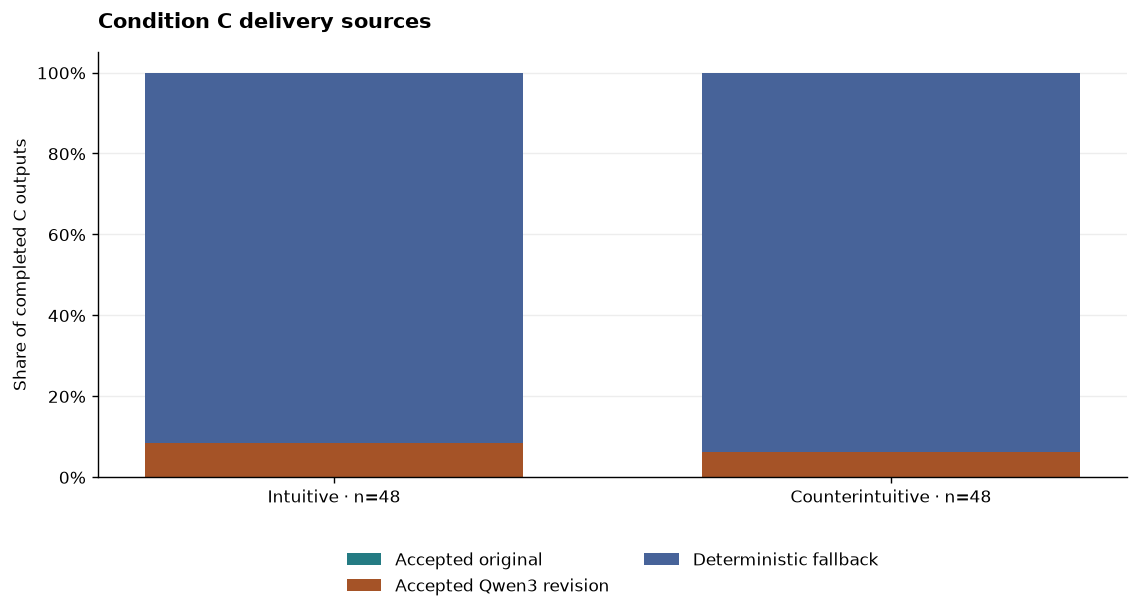

In [8]:
if results:
    interventions = pd.DataFrame(results["interventions"])
    interventions["intervention_rate"] = interventions["interventions"] / interventions["completed"]
    display(interventions[["variant", "completed", "interventions", "intervention_rate",
                           "revision_accepted", "revision_rejected", "fallback_used", "verified_complete"]])
    probes = pd.DataFrame(results["fictional_verifier_probes"])
    display(probes.drop(columns=["explanation"]))
    errors = probes[probes["expected_error"]]
    complete_controls = probes[probes["probe"] == "correct control"]
    display(pd.Series({
        "Explicitly detected errors": int(errors["detected"].sum()),
        "Ambiguous errors rejected without explicit detection": int(
            (errors["ambiguous"] & ~errors["detected"] & ~errors["draft_accepted"]).sum()),
        "Errors silently missed and accepted": int((errors["missed"] & errors["draft_accepted"]).sum()),
        "Complete correct controls rejected": int((~complete_controls["draft_accepted"]).sum()),
    }, name="Exploratory probe counts").to_frame())
    display(figures["04_verification_outcomes"])

## Paired H3 contrasts

Differences are counterintuitive minus intuitive. Percentile 95% confidence intervals use 10,000 resamples of whole synthetic profiles with seed 380. Each draw preserves the variants and conditions. The main analysis uses valid pairs. The sensitivity analysis assigns terminal failures zero on bounded agreement and ranking metrics. Family and challenge-attribute contrasts are descriptive. Attribute strata flag whether either member has the property, preserving the match.

,stratum,condition,policy,pairs,mean_difference,ci95_low,ci95_high
0,all,A,valid_pairs,44,-1.000,-1.227,-0.762
1,all,A,failed_outputs_zero,48,-0.896,-1.125,-0.667
7,all,B,valid_pairs,48,-0.229,-0.479,-0.021
8,all,B,failed_outputs_zero,48,-0.229,-0.479,-0.021
14,all,C,valid_pairs,48,0.000,0.000,0.000
15,all,C,failed_outputs_zero,48,0.000,0.000,0.000


,stratum,condition,pairs,mean_difference,ci95_low,ci95_high
23,renal-utilization,A,22,-1.455,-1.696,-1.200
30,renal-utilization,B,24,-0.167,-0.417,0.042
37,renal-utilization,C,24,0.000,0.000,0.000
46,age-physiology,A,22,-0.545,-0.857,-0.250
53,age-physiology,B,24,-0.292,-0.708,0.042
60,age-physiology,C,24,0.000,0.000,0.000
69,mixed_direction=False,A,13,-0.923,-1.385,-0.462
76,mixed_direction=False,B,13,-0.231,-0.615,0.000
83,mixed_direction=False,C,13,0.000,0.000,0.000
92,mixed_direction=True,A,31,-1.032,-1.273,-0.781


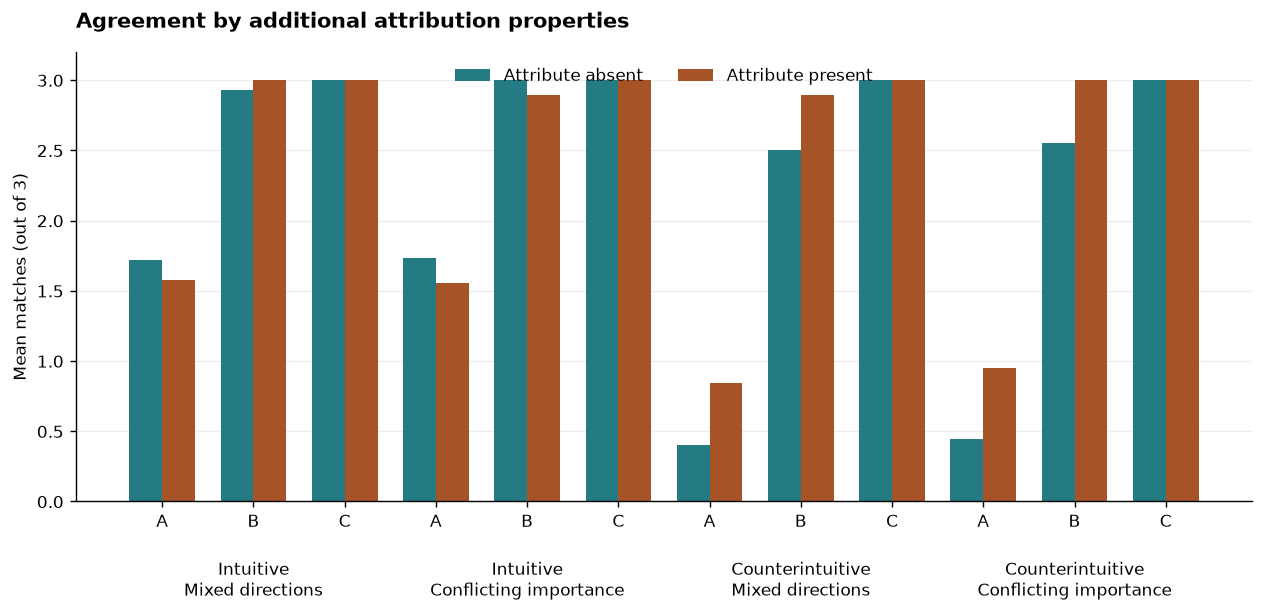

In [9]:
if results:
    paired = pd.DataFrame(results["paired"])
    signed = paired.query("metric == 'signed_top_three_agreement'")
    columns = ["stratum", "condition", "policy", "pairs", "mean_difference", "ci95_low", "ci95_high"]
    display(signed.query("stratum == 'all'")[columns].round(3))
    display(signed.query("stratum != 'all' and policy == 'valid_pairs'")[
        [c for c in columns if c != "policy"]].round(3))
    # All subgroup failure-inclusive rows remain available in signed.
    display(figures["05_attribution_properties"])

In [10]:
if results and run["execution_mode"] == "real" and run["state"]["pause_reason"] is None:
    primary = paired.query("stratum == 'all' and metric == 'signed_top_three_agreement' and policy == 'valid_pairs'")
    for row in primary.itertuples():
        if pd.isna(row.ci95_high):
            interpretation = "Insufficient valid pairs to estimate the contrast."
        elif row.ci95_high < 0:
            interpretation = "The interval supports lower agreement under reversal in this condition."
        elif row.ci95_low > 0:
            interpretation = "The interval favors higher agreement under reversal in this condition."
        elif row.ci95_low == row.ci95_high == 0:
            interpretation = "Observed paired differences were zero."
        else:
            interpretation = "The interval includes zero, leaving the directional contrast inconclusive."
        display(Markdown(f"**Condition {row.condition}.** {interpretation}"))

**Condition A.** The interval supports lower agreement under reversal in this condition.

**Condition B.** The interval supports lower agreement under reversal in this condition.

**Condition C.** Observed paired differences were zero.

## Predicted-risk sensitivity

Patient features are held fixed. Predicted probability changes with the model switch and is visible to A and B. The analysis below groups saved pairs into fixed descriptive bands of absolute probability change. Each mean uses complete pairs for that condition, and the sample standard deviation describes dispersion of the paired differences. The bands and this supplement were chosen during finalization. They leave the primary bootstrap unchanged.

A more adverse contrast in a higher band can reflect the probability cue, the size or pattern of the SHAP changes, or differences in the profiles represented in that band. The experiment measures the model switch as a whole. Its design cannot attribute all observed loss exclusively to reversed coefficient signs.

In [11]:
if results:
    risk_sensitivity = predicted_risk_sensitivity(results)
    risk_pairs = pd.DataFrame(risk_sensitivity["pairs"])
    risk_columns = ["intuitive_probability", "counterintuitive_probability",
                    "probability_change", "absolute_probability_change"]
    display(risk_pairs.groupby("family")[risk_columns].mean().mul(100).round(1).rename(columns={
        "intuitive_probability": "Intuitive mean (%)",
        "counterintuitive_probability": "Counterintuitive mean (%)",
        "probability_change": "Signed change (pp)",
        "absolute_probability_change": "Absolute change (pp)",
    }))
    display(pd.DataFrame(risk_sensitivity["strata"]).round(3))
    # risk_pairs retains the per-profile A/B differences and both variants' challenge attributes.

,Intuitive mean (%),Counterintuitive mean (%),Signed change (pp),Absolute change (pp)
family,,,,
age-physiology,34.5,16.3,-18.2,18.2
renal-utilization,37.8,12.0,-25.8,25.8


,band,condition,selected_pairs,complete_pairs,mean_difference,paired_difference_sd
0,<15 pp,A,17,15,-0.467,0.834
1,<15 pp,B,17,17,-0.118,0.485
2,15–<25 pp,A,16,16,-1.188,0.655
3,15–<25 pp,B,16,16,-0.375,1.025
4,≥25 pp,A,15,13,-1.385,0.650
5,≥25 pp,B,15,15,-0.200,0.862


## Optional observational MIMIC-IV extension

The aggregate screen reads the saved 72-case XGBoost reference. Prespecified operational cutoffs are 70 years, 2 prior admissions, and 1.5 mg/dL creatinine. The screen assumes a familiar positive local direction at or above each cutoff, and applies the same mixed-direction and importance thresholds as the synthetic analysis. These are screening assumptions. A local sign depends on the feature value, reference and model interactions. Observational counts stay outside the primary H3 estimate.

In [12]:
if SCREEN_PINNED_MIMIC:
    try:
        display(screen_saved_cases())
    except (FileNotFoundError, PermissionError) as error:
        display(Markdown(f"Saved private attributions are unavailable ({type(error).__name__})."))
else:
    display(Markdown("Optional MIMIC-IV screen disabled."))

Optional MIMIC-IV screen disabled.

## Representative matched example · Wholly synthetic

The example shows both models on the same feature values. Original A and B excerpts and the C output come directly from the saved responses. The displayed mathematical interpretation uses the signed log-odds contributions.

In [13]:
if results:
    example = next((e for e in results["examples"] if e["profile_id"] == "synthetic-00533"),
                   results["examples"][0] if results["examples"] else None)
    if example:
        display(Markdown(f'**Wholly synthetic profile {example["profile_id"]}**'))
        display(pd.DataFrame(example["variants"][0]["features"])[["label", "value", "unit"]])
        records = {(r["case_id"], r["condition"]): r for r in run["state"]["records"].values()}
        for variant in example["variants"]:
            display(Markdown(f'**{variant["variant"].title()} model** · probability {variant["predicted_risk"]:.2%}'))
            refs = pd.DataFrame(variant["shap"]["contributions"]).sort_values("rank")
            display(refs[["label", "shap", "rank"]].round(3))
            for condition, answer in variant["explanations"].items():
                print(f"{condition} — {answer['explanation'][:450] if answer else 'No valid output'}")
            grounded = variant["explanations"]["B"]
            if grounded:
                print("B JSON directions:", ", ".join(f'{d["feature"]} {d["direction"]}' for d in grounded["drivers"]))
            trace = records[variant["case_id"], "C"].get("verification")
            if trace:
                print("C delivery:", trace["source"].replace("_", " "))
            signed_targets = refs[refs["feature"].isin(variant["targeted_features"])]
            print("Target contributions in log-odds:", ", ".join(
                f"{r.label} {r.shap:+.3f}" for r in signed_targets.itertuples()))
            if (variant["case_id"] == "synthetic-00533-renal-utilization-counterintuitive"
                    and grounded and trace and trace["fallback_used"]
                    and any(c["status"] == "ambiguous" for c in trace["original"]["narrative"]["claims"])
                    and sha256(grounded["explanation"].encode()).hexdigest() ==
                    "eb7152237ddd5ceab96aa47128dfd852700154ed15fe025eb59e5423d8133d26"):
                display(Markdown(
                    "**Independent reading of the saved B draft.** The JSON correctly gives negative "
                    "directions for prior admissions and creatinine and a positive direction for sodium. "
                    "The prose communicates the opposite directions. The verifier rejected the ambiguous "
                    "clauses without explicitly identifying those contradictions. The fallback states the "
                    "directions shown by the saved SHAP reference."
                ))

**Wholly synthetic profile synthetic-00533**

,label,value,unit
0,Age,54.00,years
1,Prior hospital admissions,3.00,admissions
2,Creatinine,1.53,mg/dL
3,Hemoglobin,12.20,g/dL
4,Sodium,135.80,mmol/L
5,Heart rate,87.00,bpm


**Intuitive model** · probability 43.33%

,label,shap,rank
1,Prior hospital admissions,0.742,1
2,Creatinine,0.329,2
4,Sodium,0.074,3
3,Hemoglobin,0.065,4
0,Age,-0.033,5
5,Heart rate,0.005,6


A — The model's predicted readmission risk is 43.33%. The strongest drivers are prior hospital admissions and creatinine levels, which increase risk, while hemoglobin and sodium levels decrease it.
B — The model predicts a 43.33% risk of readmission. Prior admissions and creatinine levels most strongly increase predicted risk, while sodium levels also contribute positively.
C — The model estimates a 43.33% readmission probability. prior_admissions increases the model's predicted risk relative to the model reference, while creatinine increases the model's predicted risk relative to the model reference, while sodium increases the model's predicted risk relative to the model reference.
B JSON directions: prior_admissions positive, creatinine positive, sodium positive
C delivery: deterministic fallback
Target contributions in log-odds: Prior hospital admissions +0.742, Creatinine +0.329


**Counterintuitive model** · probability 8.23%

,label,shap,rank
1,Prior hospital admissions,-0.742,1
2,Creatinine,-0.329,2
4,Sodium,0.074,3
3,Hemoglobin,0.065,4
0,Age,-0.033,5
5,Heart rate,0.005,6


A — The model's predicted readmission risk is 8.23%. The strongest drivers are prior hospital admissions and creatinine levels, which increase risk, while hemoglobin and sodium levels decrease it.
B — The model predicts an 8.2% risk of readmission. Prior admissions and creatinine most strongly influence the prediction, increasing risk, while sodium decreases it.
C — The model estimates a 8.23% readmission probability. prior_admissions decreases the model's predicted risk relative to the model reference, while creatinine decreases the model's predicted risk relative to the model reference, while sodium increases the model's predicted risk relative to the model reference.
B JSON directions: prior_admissions negative, creatinine negative, sodium positive
C delivery: deterministic fallback
Target contributions in log-odds: Prior hospital admissions -0.742, Creatinine -0.329


**Independent reading of the saved B draft.** The JSON correctly gives negative directions for prior admissions and creatinine and a positive direction for sodium. The prose communicates the opposite directions. The verifier rejected the ambiguous clauses without explicitly identifying those contradictions. The fallback states the directions shown by the saved SHAP reference.

## Discussion and Experiment 4 handoff

The reference-run paired estimates support H3 in A and show a smaller adverse effect in B. C's zero difference reflects the complete verification system, which relied heavily on deterministic fallback. The controlled synthetic design supports conclusions about this benchmark. The risk-band analysis is descriptive, and the structured findings establish reported directions rather than the model's internal reasoning.

Experiment 4 should use a separately labeled verifier challenge set. It should measure false positives on mathematically faithful unfamiliar prose, false negatives on subtle contradictions, and correct rejections for structured errors. It should track ambiguous semantic cases separately, distinguish Qwen3 revision success from fallback dependence, and assess how constrained explanations affect readability and informativeness.